# 01 · Degradations and classical restoration baselines

This notebook builds the image damage used throughout the project and measures how well classical filters repair it.

| Section | What it builds | Used later by |
|---|---|---|
| 2 | `degradations.py`: 7 physically motivated degradations | 05 (detection sweep), 06 (residual probes) |
| 3 | PSNR (from scratch) and SSIM | every notebook |
| 4–5 | 4 classical filters, tuned per degradation → `best_classical.json` | 05 and 06 (the "classical" restorer) |
| 6 | Colour-space denoising experiment | — |
| 7 | Grayscale and contrast experiments, and fixes matched to blur and colour cast | — |

**Conventions shared by all notebooks:**
- Images are `float32`, **RGB**, shape `(H, W, 3)`, values in **[0, 1]**.
- A degradation is a function `f(img, severity, rng) -> img` with the same shape, dtype and range.
- All randomness goes through an `np.random.Generator` passed in, so every result is reproducible.

Test cells print `PASS` or `FAIL` for the properties later sections rely on. Runs on CPU (Kaggle or Colab).

## 0 · Setup

Installs the libraries the notebook needs (OpenCV for image operations and filters, scikit-image for SSIM, pandas for results tables), sets the random seed and output folder, and defines small helpers used by every section.

In [1]:
!pip -q install scikit-image opencv-python-headless pandas

In [2]:
import os, glob, json, time, itertools
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
from skimage.metrics import structural_similarity

SEED = 0

# Paths work on both Kaggle and Colab. On Kaggle, anything under /kaggle/working becomes the notebook's
# output when it is committed; notebooks 05 and 06 get degradations.py and best_classical.json from there.
IN_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if IN_KAGGLE else "."
OUT_DIR = f"{WORK}/outputs/01"
os.makedirs(OUT_DIR, exist_ok=True)
print("Kaggle" if IN_KAGGLE else "Colab/local", "| outputs ->", OUT_DIR)

Kaggle | outputs -> /kaggle/working/outputs/01


In [3]:
# --- helpers used by every section: loading, listing, plotting, test output ---------
def load_rgb(path):
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return img[:, :, ::-1].astype(np.float32) / 255.0          # BGR uint8 -> RGB float [0, 1]

def list_images(folder):
    exts = ("*.png", "*.jpg", "*.jpeg", "*.bmp", "*.tif")
    return sorted(p for e in exts for p in glob.glob(os.path.join(folder, "**", e), recursive=True))

def show_grid(images, titles=None, cols=4, size=3, save=None):
    rows = int(np.ceil(len(images) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size), squeeze=False)
    for i, ax in enumerate(axes.ravel()):
        ax.axis("off")
        if i < len(images):
            im = images[i]
            ax.imshow(np.clip(im, 0, 1), cmap="gray" if im.ndim == 2 else None, vmin=0, vmax=1)
            if titles: ax.set_title(titles[i], fontsize=9)
    plt.tight_layout()
    if save: plt.savefig(save, dpi=150, bbox_inches="tight")
    plt.show()

def check(cond, msg):
    print(("PASS  " if cond else "FAIL  ") + msg)
    return cond

## 1 · Data

**Dataset:** BSD500 (Berkeley Segmentation Dataset), 500 natural colour photos of 481 × 321 pixels, split into `train` (200), `test` (200) and `val` (100). This notebook uses the **100 `val` images**. DnCNN (notebook 04) trains on `train` + `test`, so these images are never used for training. The `val` split contains most of CBSD68, the standard colour-denoising benchmark, so results can be compared with published DnCNN numbers.

**Tuning and test split:** the first 4 images (in sorted order) form a **tuning set**, used only to choose filter parameters. The other 96 form the **test set** that every result is reported on. Choosing parameters on the test images would make the classical filters look better than they are.

If no dataset is attached, the cell falls back to 4 scikit-image sample photos: enough to check that the code runs, not for real results.

In [4]:
DATA_DIR = "/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/val"   # 100 images, never used for DnCNN training

def find_dataset():
    for root in ["/kaggle/input", "data"]:
        for d in sorted(glob.glob(os.path.join(root, "**"), recursive=True)):
            if os.path.isdir(d) and "68" in os.path.basename(d) and len(list_images(d)) >= 60:
                # Fallback search, used only if DATA_DIR is empty. CBSD68 copies often ship noisy
                # versions too, so prefer a folder that looks clean
                if not any(k in d.lower() for k in ("noisy", "sigma", "_n", "noise")):
                    return d
    return None

DATA_DIR = DATA_DIR or find_dataset()
if DATA_DIR is None:
    from skimage import data as skdata
    DATA_DIR = f"{WORK}/data/fallback"; os.makedirs(DATA_DIR, exist_ok=True)
    for name in ["astronaut", "coffee", "chelsea", "rocket"]:
        cv2.imwrite(f"{DATA_DIR}/{name}.png", getattr(skdata, name)()[:, :, ::-1])
    print("No CBSD68 found, using 4 fallback images (fine for writing code, not for results)")

paths = list_images(DATA_DIR)
images = [load_rgb(p) for p in paths]
N_TUNE = 4 if len(images) >= 20 else 1
tune_imgs, test_imgs = images[:N_TUNE], images[N_TUNE:]
print(f"{DATA_DIR}: {len(images)} images -> {len(tune_imgs)} tuning, {len(test_imgs)} test")
if len(images) not in (4, 100):
    print(f"WARNING: BSD500 val has 100 images, found {len(images)}. Check DATA_DIR.")
print("example:", images[0].shape, images[0].dtype, f"[{images[0].min():.2f}, {images[0].max():.2f}]")

/kaggle/input/datasets/balraj98/berkeley-segmentation-dataset-500-bsds500/images/val: 100 images -> 4 tuning, 96 test
example: (481, 321, 3) float32 [0.00, 1.00]


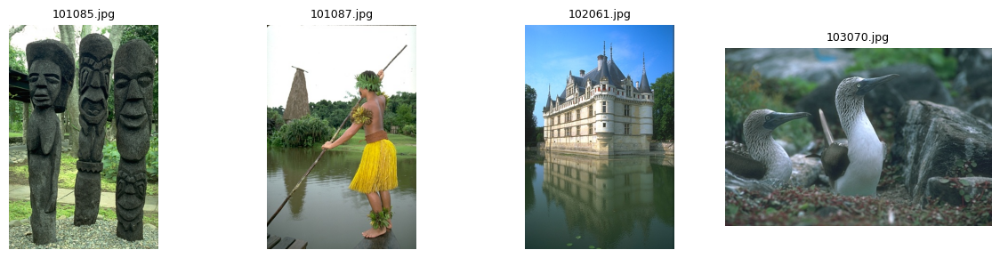

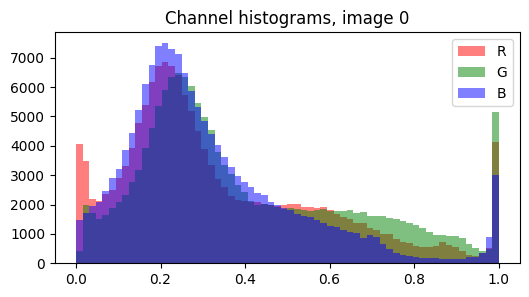

In [5]:
# Look at the data before using it: the first 4 images (the tuning set), and the R, G, B histograms of image 0.
# In natural images the three histograms overlap strongly: the channels are highly correlated (see section 6).
show_grid(images[:4], [os.path.basename(p) for p in paths[:4]])
fig, ax = plt.subplots(figsize=(6, 3))
for c, col in enumerate("rgb"):
    ax.hist(images[0][..., c].ravel(), bins=64, color=col, alpha=0.5, label=col.upper())
ax.set_title("Channel histograms, image 0"); ax.legend(); plt.show()
x = images[0]   # used by the test cells below

## 2 · Degradation module → `degradations.py`

The next cell **writes a Python file** instead of defining the functions in the notebook, so notebooks 05 and 06 can `from degradations import degrade` and apply exactly the same damage.

### What each degradation models

| Name | Physical cause | Model | Severity knob |
|---|---|---|---|
| `gaussian` | sensor read noise, thermal noise | $y = x + n,\ n \sim \mathcal N(0, (\sigma/255)^2)$ i.i.d. per pixel and channel | $\sigma$ on the 0–255 scale |
| `poisson` | photon shot noise: light arrives in discrete photons | $y = \mathrm{Poisson}(p\,x)/p$, so $\mathrm{Var}[y] = x/p$ (**signal-dependent**) | peak photon count $p$ (lower = noisier) |
| `salt_pepper` | dead/stuck pixels, transmission bit errors | fraction $a$ of pixels set to 0 or 1 with equal probability | fraction $a$ |
| `blur` | defocus, camera shake (approx.) | $y = k_\sigma * x$, Gaussian kernel | kernel std $\sigma$ in pixels |
| `jpeg` | lossy storage / transmission | encode–decode at quality $q$ | quality $q$ (lower = worse) |
| `color_cast` | wrong white balance | per-channel gains $(1+s,\ 1,\ 1-s)$ | strength $s$ |
| `low_light` | under-exposure; dark images are also noisier | darken, then add shot + read noise | level $\ell \in [0, 1]$ |

### Implementation notes
- **gaussian:** `rng.normal(0, sigma / 255, img.shape)`, added in float. The functions never clip; `degrade()` clips once at the end.
- **poisson:** `rng.poisson(peak * img) / peak`. The noise is stronger in bright regions in absolute terms but weaker relative to the signal, since SNR $= \sqrt{p\,x}$, so dark regions are the noisiest.
- **salt_pepper:** corrupts whole **pixels** (all three channels together, giving black or white specks), which is how dead or stuck sensor pixels behave.
- **blur:** `cv2.GaussianBlur(img, (0, 0), sigma)` picks the kernel size from σ (about $6\sigma$, since ±3σ covers 99.7% of the mass). Reflected borders stop the edges darkening.
- **jpeg:** converts to `uint8` BGR for OpenCV's codec, encodes and decodes at quality $q$, and converts back. Notebook 02 rebuilds this pipeline from scratch.
- **to_grayscale:** BT.601 luma $Y = 0.299R + 0.587G + 0.114B$ or the plain mean, returned as 3 equal channels.
- **color_cast:** multiplies the channels by $(1 + s,\ 1,\ 1 - s)$; $s = 0$ is exactly the identity.
- **low_light:** darkening and a gamma curve, $x_d = g\,x^{\gamma}$ with $g = 1 - 0.8\ell$ and $\gamma = 1 + 2\ell$, then shot noise with peak $p = 200(1 - \ell) + 5$ photons and Gaussian read noise with std $0.01 + 0.04\ell$ (on the [0, 1] scale). Both noise terms are skipped at $\ell = 0$, so level 0 is exactly the identity.

In [6]:
%%writefile degradations.py
"""Image degradations. Convention: float32 RGB in [0, 1], shape (H, W, 3).
Every function takes and returns float images in [0, 1]; degrade() clips once at the end."""
import numpy as np
import cv2


def add_gaussian_noise(img, sigma, rng):
    """Additive white Gaussian noise. `sigma` is on the 0-255 scale (e.g. 15, 25, 50)."""
    # Zero-mean Gaussian noise with the same shape as the image. "White" = each value is drawn
    # independently of its neighbours (flat power spectrum). sigma is given on the 0-255 scale,
    # so divide by 255 to match our [0, 1] images. Working in float also avoids uint8 overflow.
    noise = rng.normal(0.0, sigma / 255.0, img.shape)
    return img + noise                       # no clipping here: degrade() clips once


def add_poisson_noise(img, peak, rng):
    """Shot noise: y = Poisson(peak * x) / peak. Lower `peak` = fewer photons = noisier."""
    # peak * x = expected photon count per pixel; sampling a Poisson count models the randomness
    # of photon arrival. Dividing by peak maps it back to [0, 1]. Var[y] = x / peak, so the noise
    # depends on the signal: SNR = sqrt(peak * x), which is worse in dark regions.
    return rng.poisson(peak * img) / peak


def add_salt_pepper(img, amount, rng):
    """Set a fraction `amount` of pixels to black (0) or white (1), equal odds, all three channels together."""
    # Per-PIXEL corruption (all 3 channels together), which is how dead/stuck sensor pixels behave.
    # A 2-D mask indexes the first two axes, so sp_noisy[mask] = 1.0 sets R, G and B at once.
    sp_noisy = img.copy()
    h, w = img.shape[:2]
    corrupt = rng.random((h, w)) < amount                     # which pixels get corrupted
    salt = rng.integers(0, 2, size=(h, w)).astype(bool)       # half white, half black
    sp_noisy[corrupt & salt] = 1.0
    sp_noisy[corrupt & ~salt] = 0.0
    return sp_noisy


def gaussian_blur(img, sigma, rng=None):
    """Gaussian blur with std `sigma` pixels, reflect borders."""
    # Kernel size (0, 0) lets OpenCV choose it from sigma (about 6*sigma covers +-3 sigma).
    # Reflect borders so the image edges don't darken.
    return cv2.GaussianBlur(img, (0, 0), sigmaX=sigma, borderType=cv2.BORDER_REFLECT)


def jpeg_compress(img, quality, rng=None):
    """Round-trip through JPEG at `quality` (1-100). cv2 wants uint8 BGR in, gives uint8 BGR out."""
    # The one place we leave our convention: OpenCV's JPEG codec needs uint8 BGR,
    # so convert float RGB [0, 1] -> uint8 BGR, encode/decode, then convert back.
    u8_bgr = (np.clip(img, 0, 1) * 255).round().astype(np.uint8)[:, :, ::-1]
    ok, buf = cv2.imencode(".jpg", u8_bgr, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    if not ok:
        raise RuntimeError("JPEG encoding failed")
    decoded = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    return decoded[:, :, ::-1].astype(np.float32) / 255.0


def to_grayscale(img, method="luma", rng=None):
    """3-channel grey image. method: 'luma' (BT.601 weights) or 'average'."""
    r, g, b = img[..., 0], img[..., 1], img[..., 2]          # RGB order
    if method == "luma":
        grey = 0.299 * r + 0.587 * g + 0.114 * b             # BT.601: eye is most sensitive to green
    elif method == "average":
        grey = (r + g + b) / 3.0
    else:
        raise ValueError(f"unknown method: {method}")
    return np.stack([grey, grey, grey], axis=-1)              # back to 3 channels


def color_cast(img, strength, rng=None):
    """White-balance error: gains (1 + s, 1, 1 - s) on (R, G, B). strength=0 -> identity."""
    gains = np.array([1 + strength, 1.0, 1 - strength], dtype=np.float32)   # RGB order: warmer image
    return img * gains                                         # broadcasts over the channel axis


def low_light(img, level, rng):
    """Darken + gamma, then add shot and read noise. level=0 -> identity, level->1 -> very dark and noisy."""
    # 1. darken + gamma (level 0 -> gain 1, gamma 1 -> identity).
    #    Model: gain * x**gamma (a gamma curve, then an exposure scale).
    gain = 1.0 - 0.8 * level
    gamma = 1.0 + 2.0 * level
    x = gain * np.power(img, gamma)
    if level == 0:
        return x                                               # no noise at level 0 -> exact identity

    # 2. shot noise: fewer photons as level rises
    peak = 200.0 * (1.0 - level) + 5.0
    x = rng.poisson(x * peak) / peak

    # 3. read noise: signal-independent Gaussian, grows with level (already on the [0, 1] scale)
    read_sigma = 0.01 + 0.04 * level
    return x + rng.normal(0.0, read_sigma, x.shape)


# name -> (function, severities from mild to severe)
DEGRADATIONS = {
    "gaussian":    (add_gaussian_noise, [5, 15, 25, 35, 50]),
    "poisson":     (add_poisson_noise,  [100, 50, 20, 10, 5]),
    "salt_pepper": (add_salt_pepper,    [0.01, 0.03, 0.05, 0.1, 0.2]),
    "blur":        (gaussian_blur,      [0.5, 1.0, 1.5, 2.0, 3.0]),
    "jpeg":        (jpeg_compress,      [90, 70, 50, 30, 10]),
    "color_cast":  (color_cast,         [0.1, 0.2, 0.3, 0.4, 0.5]),
    "low_light":   (low_light,          [0.2, 0.4, 0.6, 0.8, 0.9]),
}


def degrade(img, name, severity, rng):
    """The one entry point other notebooks use. Clips to [0, 1] once, here."""
    fn, _ = DEGRADATIONS[name]
    out = fn(img.astype(np.float32), severity, rng=rng)
    return np.clip(out, 0, 1).astype(np.float32)

Writing degradations.py


In [7]:
import importlib, degradations
importlib.reload(degradations)
from degradations import DEGRADATIONS, degrade
import degradations as D

### 2.1 · Tests

These check the *statistics* of each degradation, not just shapes. Most use a flat grey image (0.5 everywhere) so that clipping cannot distort the numbers. Expected: the Gaussian residual has std σ/255 and mean 0; Poisson keeps the mean with variance $x/p$; salt & pepper changes about the requested fraction of pixels, half white and half black; blur keeps the mean and lowers total variation; JPEG error falls as quality rises; luma of pure red is 0.299; colour cast and low light are the identity at 0, and low light darkens steadily with level.

In [8]:
def run_degradation_tests():
    r = lambda: np.random.default_rng(123)
    flat = np.full((256, 256, 3), 0.5, np.float32)
    ok = True

    # Contract: shape / dtype / range for every degradation and severity, on a real image
    bad = []
    for name, (_, levels) in DEGRADATIONS.items():
        for s in levels:
            y = degrade(x, name, s, r())
            if y.shape != x.shape or y.dtype != np.float32 or y.min() < 0 or y.max() > 1:
                bad.append((name, s))
    ok &= check(not bad, f"shape/dtype/range contract {'' if not bad else bad}")

    # Gaussian: residual std ~ sigma/255, mean ~ 0
    d = degrade(flat, "gaussian", 25, r()) - flat
    ok &= check(abs(d.std() - 25 / 255) < 0.03 * 25 / 255 and abs(d.mean()) < 2e-3,
                f"gaussian sigma=25: std {d.std() * 255:.2f}/255 (want 25), mean {d.mean():+.4f}")

    # Poisson: mean preserved, variance = x / peak
    y = degrade(flat, "poisson", 20, r())
    ok &= check(abs(y.mean() - 0.5) < 5e-3 and abs(y.var() - 0.5 / 20) < 0.05 * 0.5 / 20,
                f"poisson peak=20: mean {y.mean():.4f} (want 0.5), var {y.var():.4f} (want {0.5 / 20:.4f})")

    # Salt & pepper: ~amount of values changed, roughly half salt and half pepper
    y = degrade(flat, "salt_pepper", 0.1, r())
    changed = (y != 0.5); frac = changed.mean(); salt = (y[changed] == 1).mean()
    ok &= check(abs(frac - 0.1) < 0.01 and abs(salt - 0.5) < 0.05 and np.isin(y[changed], [0, 1]).all(),
                f"salt_pepper 0.1: {frac:.3f} of values changed, {salt:.2f} of them salt")

    # Blur: mean preserved, more blur = smoother (lower total variation)
    tv = lambda im: np.abs(np.diff(im, axis=0)).mean() + np.abs(np.diff(im, axis=1)).mean()
    b1, b3 = degrade(x, "blur", 1.0, r()), degrade(x, "blur", 3.0, r())
    ok &= check(abs(b1.mean() - x.mean()) < 2e-3 and tv(b3) < tv(b1) < tv(x),
                f"blur: mean shift {abs(b1.mean() - x.mean()):.4f}, TV {tv(x):.4f} > {tv(b1):.4f} > {tv(b3):.4f}")

    # JPEG: quality goes up -> error goes down, and q=95 is close to the original
    errs = [np.abs(degrade(x, "jpeg", q, r()) - x).mean() for q in (10, 30, 50, 70, 95)]
    ok &= check(all(a > b for a, b in zip(errs, errs[1:])) and errs[-1] < 0.01,
                "jpeg: mean abs error falls with quality " + " > ".join(f"{e:.4f}" for e in errs))

    # Grayscale: equal channels; known values on pure red
    red = np.zeros((4, 4, 3), np.float32); red[..., 0] = 1
    gl, ga = D.to_grayscale(red, "luma"), D.to_grayscale(red, "average")
    ok &= check(np.allclose(gl[..., 0], gl[..., 1]) and np.allclose(gl[..., 0], 0.299, atol=1e-3)
                and np.allclose(ga[..., 0], 1 / 3, atol=1e-3),
                f"grayscale: pure red -> luma {gl[0, 0, 0]:.3f} (want 0.299), average {ga[0, 0, 0]:.3f} (want 0.333)")

    # Colour cast: identity at 0, R up and B down otherwise
    c0, c3 = D.color_cast(flat, 0.0), D.color_cast(flat, 0.3)
    ok &= check(np.allclose(c0, flat) and c3[..., 0].mean() > 0.5 > c3[..., 2].mean(),
                f"color_cast: identity at 0; s=0.3 gives R {c3[..., 0].mean():.2f}, B {c3[..., 2].mean():.2f}")

    # Low light: ~identity at 0, monotonically darker with level
    means = [degrade(x, "low_light", l, r()).mean() for l in (0.0, 0.2, 0.4, 0.6, 0.8, 0.9)]
    ident = np.abs(degrade(x, "low_light", 0.0, r()) - x).mean()
    ok &= check(ident < 0.01 and all(a > b for a, b in zip(means, means[1:])),
                f"low_light: identity error at 0 = {ident:.4f}; means " + " > ".join(f"{m:.3f}" for m in means))

    print("\nALL DEGRADATION TESTS PASS" if ok else "\nfix the FAILs above before moving on")

run_degradation_tests()

PASS  shape/dtype/range contract 
PASS  gaussian sigma=25: std 25.01/255 (want 25), mean -0.0001
PASS  poisson peak=20: mean 0.4994 (want 0.5), var 0.0247 (want 0.0250)
PASS  salt_pepper 0.1: 0.099 of values changed, 0.50 of them salt
PASS  blur: mean shift 0.0000, TV 0.1251 > 0.0428 > 0.0173
PASS  jpeg: mean abs error falls with quality 0.0515 > 0.0363 > 0.0304 > 0.0246 > 0.0013
PASS  grayscale: pure red -> luma 0.299 (want 0.299), average 0.333 (want 0.333)
PASS  color_cast: identity at 0; s=0.3 gives R 0.65, B 0.35
PASS  low_light: identity error at 0 = 0.0000; means 0.355 > 0.221 > 0.140 > 0.091 > 0.060 > 0.049

ALL DEGRADATION TESTS PASS


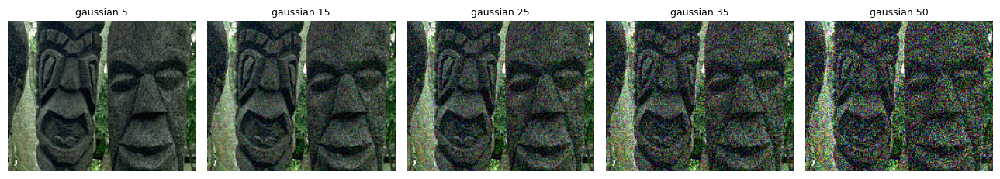

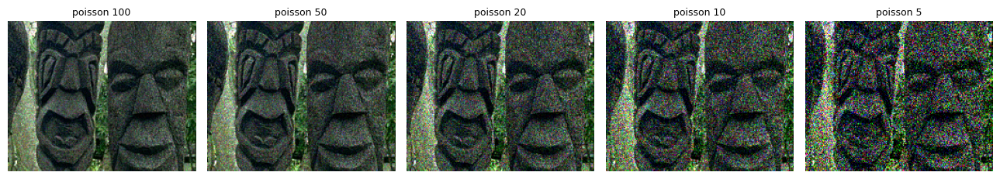

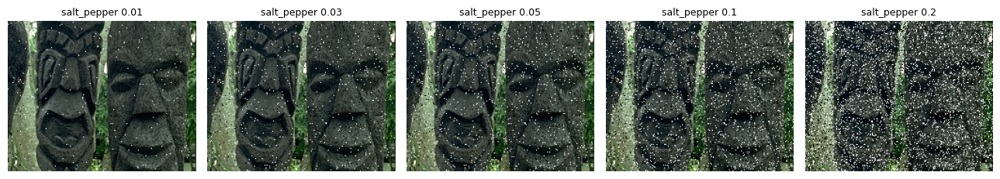

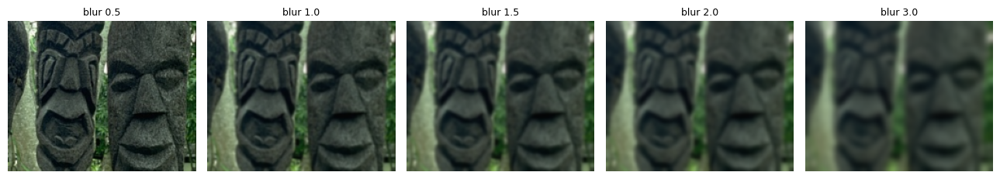

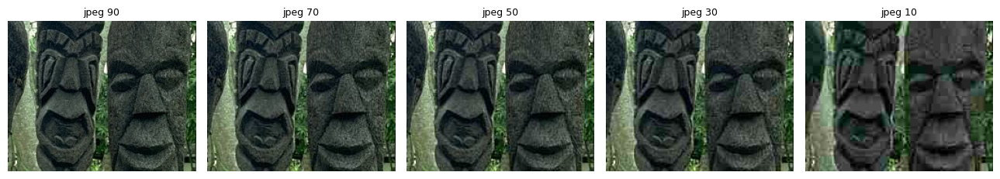

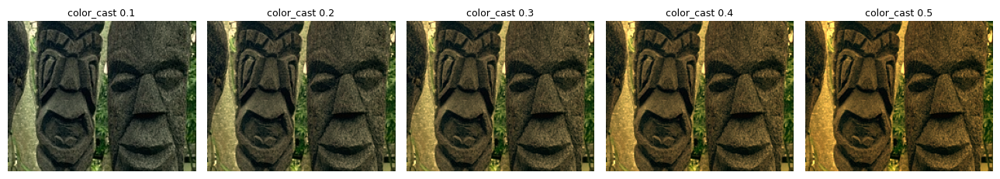

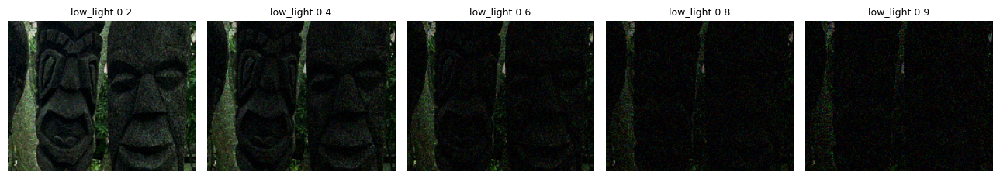

In [9]:
# Visual check: one row per degradation, mild -> severe, on a crop (noise is easier to see). Saved as figures.
crop = x[60:220, 120:320]   # a crop shows noise far better than a full image
for name, (_, levels) in DEGRADATIONS.items():
    show_grid([degrade(crop, name, s, np.random.default_rng(0)) for s in levels],
              [f"{name} {s}" for s in levels], cols=5, size=2.6, save=f"{OUT_DIR}/degradations_{name}.png")

## 3 · Metrics

**PSNR** refers to peak signal-to-noise ratio. It tells us the relationship between the signal and the noise: it is the mean squared error on a log scale, relative to the largest possible value:

$$\mathrm{MSE} = \frac{1}{HWC}\sum (x - \hat x)^2, \qquad \mathrm{PSNR} = 10\log_{10}\frac{\mathrm{MAX}^2}{\mathrm{MSE}}\ \text{dB}$$

with $\mathrm{MAX} = 1$ for these images. +6 dB ≈ halving the RMS error, and identical images give $+\infty$. The MSE is computed in `float64` so tiny errors are not lost to rounding.

**SSIM** (structural similarity) compares local windows on three things: brightness (means), contrast (variances) and structure (correlation). It is closer to human judgement than PSNR, but it is still not what a detector measures, which matters in notebook 05. scikit-image's implementation is used (7 × 7 uniform window by default).

The tests check PSNR against hand-computed cases: a constant +0.1 error and a random ±0.1 error must both give exactly 20 dB.

In [10]:
def psnr(ref, test, data_range=1.0):
    """Peak signal-to-noise ratio in dB: 10 * log10(MAX^2 / MSE)."""
    # float64 so tiny errors don't vanish in float32 rounding when squared and averaged
    mse = np.mean((np.asarray(ref, np.float64) - np.asarray(test, np.float64)) ** 2)
    if mse == 0:
        return np.inf                      # identical images: no error at all
    return 10.0 * np.log10(data_range ** 2 / mse)

def ssim(ref, test):
    return structural_similarity(ref, test, channel_axis=-1, data_range=1.0)

In [11]:
y = np.clip(x + 0.1, 0, 1)
check(psnr(x, x) == np.inf or psnr(x, x) > 100, "identical images -> infinite PSNR")
check(abs(psnr(x, x + 0.1) - 20.0) < 1e-3, f"constant +0.1 error, no clipping -> {psnr(x, x + 0.1):.3f} dB (want 20)")
check(psnr(x, y) > 20.0, f"+0.1 then clip -> {psnr(x, y):.2f} dB (above 20: clipped pixels moved less than 0.1)")
e = 0.1 * np.random.default_rng(0).choice([-1.0, 1.0], size=x.shape)       # +-0.1 at random: mean 0, mean square 0.01
check(abs(psnr(x, x + e) - 20.0) < 1e-3, f"zero-mean +-0.1 error -> {psnr(x, x + e):.3f} dB (want 20; huge means you squared the mean, not the errors)")

PASS  identical images -> infinite PSNR
PASS  constant +0.1 error, no clipping -> 20.000 dB (want 20)
PASS  +0.1 then clip -> 20.16 dB (above 20: clipped pixels moved less than 0.1)
PASS  zero-mean +-0.1 error -> 20.000 dB (want 20; huge means you squared the mean, not the errors)


np.True_

## 4 · Classical restoration filters

Each wrapper takes and returns float RGB in [0, 1]. What each filter assumes about the image:

| Filter | Idea | Should suit | Fails when |
|---|---|---|---|
| Gaussian | weighted local mean | mild Gaussian noise | edges matter (blurs everything equally) |
| Median | local median: robust to outliers | **impulse** (salt & pepper) noise | dense Gaussian noise; thin lines |
| Bilateral | Gaussian in space × Gaussian in *intensity*: averages only similar neighbours | noise on images with strong edges | heavy noise (noise itself looks like an edge) |
| Non-local means | averages *patches* that look alike anywhere in a search window | Gaussian noise, textures that repeat | very heavy noise; slow |

**Implementation notes:**
- `cv2.medianBlur` accepts float32 only for k = 3 or 5, so the median goes through `uint8` (`to_u8` / `from_u8`).
- `cv2.GaussianBlur` works on float32 directly.
- `cv2.bilateralFilter` on float32: `sigma_color` is in image units, so 0.1 means "neighbours within about 0.1 in intensity count as similar".
- `cv2.fastNlMeansDenoisingColored` needs `uint8`. Its strength `h` (0–255 units) sets how different two patches may be and still be averaged, and should grow with the noise level.

`PARAM_GRID` lists the settings tried for each filter during tuning.

In [12]:
def to_u8(img):  return (np.clip(img, 0, 1) * 255).round().astype(np.uint8)
def from_u8(u8): return u8.astype(np.float32) / 255.0

def f_median(img, k=3):
    """Median of each k x k window, per channel. Robust to outliers -> ideal for salt & pepper."""
    # cv2.medianBlur only accepts float32 for k = 3 or 5, so go through uint8 for any k.
    # k must be odd so the window has a centre pixel.
    return from_u8(cv2.medianBlur(to_u8(img), k))

def f_gaussian(img, sigma=1.0):
    """Gaussian-weighted local mean. Removes noise but blurs edges just as much."""
    # (0, 0) = let OpenCV pick the kernel size from sigma; works directly on float32.
    out = cv2.GaussianBlur(img.astype(np.float32), (0, 0), sigmaX=sigma, borderType=cv2.BORDER_REFLECT)
    return np.clip(out, 0, 1)

def f_bilateral(img, d=7, sigma_color=0.1, sigma_space=5):
    """Edge-preserving smoothing: weight = spatial Gaussian x intensity Gaussian."""
    # On float32 input, sigma_color is in image units: neighbours whose colour differs by
    # much more than sigma_color get ~zero weight, so averaging stops at edges.
    # d = window diameter in pixels; sigma_space = std of the spatial Gaussian.
    out = cv2.bilateralFilter(img.astype(np.float32), d, sigma_color, sigma_space)
    return np.clip(out, 0, 1)

def f_nlmeans(img, h=10):
    """Non-local means: average pixels whose surrounding 7x7 PATCHES look alike, within a 21x21 search area."""
    # Needs uint8. h (0-255 units) sets how different two patches can be and still be averaged:
    # it should grow with the noise level. The same h is used for the colour components.
    out = cv2.fastNlMeansDenoisingColored(to_u8(img), None, h, h, 7, 21)
    return from_u8(out)

FILTERS = {"median": f_median, "gaussian": f_gaussian, "bilateral": f_bilateral, "nlmeans": f_nlmeans}

# Settings tried during tuning. The tuning cell warns if a best value lands on the edge of its grid.
PARAM_GRID = {
    "median":    [dict(k=k) for k in (3, 5, 7)],
    "gaussian":  [dict(sigma=s) for s in (0.5, 1.0, 1.5, 2.0, 3.0)],
    "bilateral": [dict(sigma_color=c, sigma_space=s) for c in (0.05, 0.1, 0.2, 0.3, 0.5) for s in (3, 5)],
    "nlmeans":   [dict(h=h) for h in (3, 6, 10, 15, 20, 30, 45, 60)],
}

In [13]:
# Quick look: each filter's output range, mean and PSNR on one noisy image (Gaussian, sigma = 25)
noisy_g = degrade(x, "gaussian", 25, np.random.default_rng(1))
for fname, f in FILTERS.items():
    out = f(noisy_g)
    print(f"{fname:10s} dtype={out.dtype}  min={out.min():.3f}  max={out.max():.3f}  "
          f"mean={out.mean():.3f} (clean {x.mean():.3f})  "
          f"changed={np.mean(np.abs(out - noisy_g) > 1e-6):.0%}  PSNR={psnr(x, out):.2f}")

median     dtype=float32  min=0.000  max=1.000  mean=0.354 (clean 0.355)  changed=99%  PSNR=22.79
gaussian   dtype=float32  min=0.006  max=0.997  mean=0.356 (clean 0.355)  changed=100%  PSNR=23.51
bilateral  dtype=float32  min=0.000  max=1.000  mean=0.355 (clean 0.355)  changed=100%  PSNR=21.58
nlmeans    dtype=float32  min=0.000  max=0.996  mean=0.353 (clean 0.355)  changed=96%  PSNR=22.46


In [14]:
# Tests: contract + each filter actually helps on the noise it's designed for
noisy_g  = degrade(x, "gaussian", 25, np.random.default_rng(1))
noisy_sp = degrade(x, "salt_pepper", 0.05, np.random.default_rng(1))
for fname, f in FILTERS.items():
    out = f(noisy_g)
    check(out.shape == x.shape and out.dtype == np.float32 and 0 <= out.min() and out.max() <= 1,
          f"{fname}: returns float32 RGB in [0, 1]")
base = psnr(x, noisy_g)
for fname, p in [("gaussian", dict(sigma=1.0)), ("bilateral", dict(sigma_color=0.2, sigma_space=5)), ("nlmeans", dict(h=15))]:
    gain = psnr(x, FILTERS[fname](noisy_g, **p)) - base
    check(gain > 1.0, f"{fname} on Gaussian sigma=25: +{gain:.2f} dB over noisy")
gain_med = psnr(x, f_median(noisy_sp, 3)) - psnr(x, noisy_sp)
gain_gau = psnr(x, f_gaussian(noisy_sp, 1.0)) - psnr(x, noisy_sp)
check(gain_med > gain_gau, f"on salt & pepper, median (+{gain_med:.1f} dB) beats Gaussian (+{gain_gau:.1f} dB)")

PASS  median: returns float32 RGB in [0, 1]
PASS  gaussian: returns float32 RGB in [0, 1]
PASS  bilateral: returns float32 RGB in [0, 1]
PASS  nlmeans: returns float32 RGB in [0, 1]
PASS  gaussian on Gaussian sigma=25: +2.95 dB over noisy
PASS  bilateral on Gaussian sigma=25: +4.27 dB over noisy
PASS  nlmeans on Gaussian sigma=25: +2.93 dB over noisy
PASS  on salt & pepper, median (+6.5 dB) beats Gaussian (+4.9 dB)


np.True_

## 5 · Experiment 1: tuned baselines and severity sweep

**Step 1, tuning.** For every (degradation, severity, filter), the parameters with the best mean PSNR on the **4 tuning images** are kept. If no filter beats doing nothing, the condition records `"none"`. The result is saved to `best_classical.json`, which notebooks 05 and 06 load as the "classical" restorer.

**Step 2, sweep.** The tuned filters are applied to the **96 test images**, and PSNR and SSIM are recorded per image (`baselines.csv`). For a given (image, degradation, severity), every filter sees the *same* noise sample, because the generator is seeded from those indices (`noise_rng`). The comparison is therefore paired: differences come from the filters, not from the noise.

**Fairness note:** each tuned filter knows the true severity, an *oracle* advantage that the blind DnCNN in notebook 04 does not have. The classical results are therefore an upper bound for these filters. The blind NL-means test below measures how much that advantage is worth.

The timing cell runs first to estimate the cost of the full run; non-local means is by far the slowest filter.

In [15]:
def noise_rng(img_idx, deg_name, sev_idx):
    # Deterministic and independent per (image, degradation, severity), identical across filters
    return np.random.default_rng([SEED, img_idx, list(DEGRADATIONS).index(deg_name), sev_idx])

# Timing estimate for the full run
t = {}
for fname, f in FILTERS.items():
    t0 = time.time(); f(noisy_g); t[fname] = time.time() - t0
n_conditions = sum(len(v[1]) for v in DEGRADATIONS.values())
tune_s = sum(t[f] * len(PARAM_GRID[f]) for f in FILTERS) * n_conditions * len(tune_imgs)
sweep_s = sum(t.values()) * n_conditions * len(test_imgs)
print({k: f"{v * 1000:.0f} ms" for k, v in t.items()})
print(f"estimated tuning {tune_s / 60:.1f} min, sweep {sweep_s / 60:.1f} min")

{'median': '1 ms', 'gaussian': '1 ms', 'bilateral': '5 ms', 'nlmeans': '277 ms'}
estimated tuning 5.3 min, sweep 15.9 min


In [16]:
best = {}   # best[deg][str(severity)] = {"filter": ..., "params": {...}, "tune_psnr": ...}  (per filter too)
for name, (_, levels) in DEGRADATIONS.items():
    best[name] = {}
    for si, s in enumerate(levels):
        noisy = [degrade(im, name, s, noise_rng(1000 + i, name, si)) for i, im in enumerate(tune_imgs)]
        per_filter = {}
        for fname, f in FILTERS.items():
            scores = [(np.mean([psnr(c, f(n, **p)) for c, n in zip(tune_imgs, noisy)]), p) for p in PARAM_GRID[fname]]
            score, params = max(scores, key=lambda z: z[0])
            per_filter[fname] = {"params": params, "tune_psnr": float(score)}
        none_psnr = float(np.mean([psnr(c, n) for c, n in zip(tune_imgs, noisy)]))
        winner = max(per_filter, key=lambda k: per_filter[k]["tune_psnr"])
        if per_filter[winner]["tune_psnr"] <= none_psnr:      # no filter helps: say so instead of picking the least bad
            winner, entry = "none", {"params": {}, "tune_psnr": none_psnr}
        else:
            entry = per_filter[winner]
        best[name][str(s)] = {"filter": winner, **entry, "per_filter": per_filter}
        print(f"{name:12s} {s!s:>5}: best = {winner:9s} {entry['params']}")

# Warn when a tuned value sits at the top of its grid: the true optimum may lie beyond it, so widen the grid
edge = set()
for name in best:
    for s_, e in best[name].items():
        for fname, pf in e["per_filter"].items():
            for key, val in pf["params"].items():
                vals = {g[key] for g in PARAM_GRID[fname]}
                if len(vals) > 1 and val == max(vals):
                    edge.add(f"{fname}.{key}={val}")
if edge:
    print("\nAt the edge of the grid (consider widening PARAM_GRID):", ", ".join(sorted(edge)))

with open(f"{OUT_DIR}/best_classical.json", "w") as fh:
    json.dump(best, fh, indent=1)

gaussian         5: best = bilateral {'sigma_color': 0.05, 'sigma_space': 5}
gaussian        15: best = bilateral {'sigma_color': 0.2, 'sigma_space': 3}
gaussian        25: best = bilateral {'sigma_color': 0.5, 'sigma_space': 3}
gaussian        35: best = bilateral {'sigma_color': 0.5, 'sigma_space': 5}
gaussian        50: best = gaussian  {'sigma': 1.5}
poisson        100: best = bilateral {'sigma_color': 0.2, 'sigma_space': 5}
poisson         50: best = bilateral {'sigma_color': 0.3, 'sigma_space': 5}
poisson         20: best = bilateral {'sigma_color': 0.5, 'sigma_space': 5}
poisson         10: best = gaussian  {'sigma': 1.5}
poisson          5: best = gaussian  {'sigma': 2.0}
salt_pepper   0.01: best = median    {'k': 3}
salt_pepper   0.03: best = median    {'k': 3}
salt_pepper   0.05: best = median    {'k': 3}
salt_pepper    0.1: best = median    {'k': 3}
salt_pepper    0.2: best = median    {'k': 3}
blur           0.5: best = none      {}
blur           1.0: best = none      {}
b

In [17]:
rows = []
for name, (_, levels) in DEGRADATIONS.items():
    for si, s in enumerate(levels):
        for i, clean in enumerate(test_imgs):
            noisy = degrade(clean, name, s, noise_rng(i, name, si))
            outs = {"none": noisy}
            for fname, f in FILTERS.items():
                outs[fname] = np.clip(f(noisy, **best[name][str(s)]["per_filter"][fname]["params"]), 0, 1)
            for fname, out in outs.items():
                rows.append(dict(degradation=name, severity=s, image=i, filter=fname,
                                 psnr=psnr(clean, out), ssim=ssim(clean, out)))
    print("done", name)

df = pd.DataFrame(rows)
df.to_csv(f"{OUT_DIR}/baselines.csv", index=False)
summary = df.groupby(["degradation", "severity", "filter"])[["psnr", "ssim"]].mean().round(3)
summary.head(15)

done gaussian
done poisson
done salt_pepper
done blur
done jpeg
done color_cast
done low_light


psnr   ssim
degradation severity filter                  
blur        0.5      bilateral  35.261  0.958
                     gaussian   32.317  0.941
                     median     28.920  0.848
                     nlmeans    33.639  0.930
                     none       36.666  0.980
            1.0      bilateral  27.772  0.810
                     gaussian   27.442  0.814
                     median     27.033  0.787
                     nlmeans    27.227  0.773
                     none       28.031  0.837
            1.5      bilateral  25.639  0.711
                     gaussian   25.561  0.720
                     median     25.479  0.711
                     nlmeans    25.256  0.677
                     none       25.764  0.731

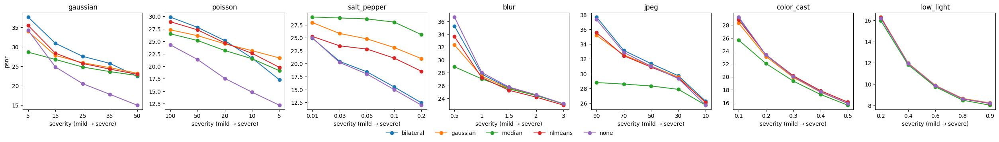

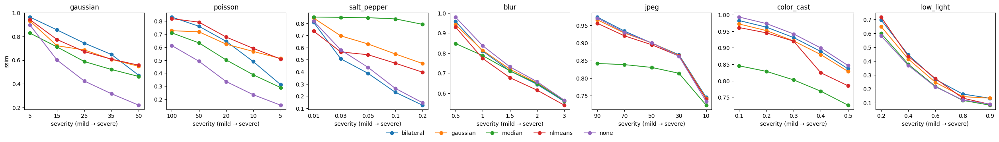

In [18]:
def plot_curves(df, metric="psnr"):
    names = list(DEGRADATIONS)
    fig, axes = plt.subplots(1, len(names), figsize=(3.6 * len(names), 3.4))
    for k, (ax, name) in enumerate(zip(axes, names)):
        sub = df[df.degradation == name].groupby(["filter", "severity"])[metric].mean().unstack(0)
        sub = sub.loc[DEGRADATIONS[name][1]]                # keep mild -> severe order (JPEG/Poisson run backwards)
        sub.index = [f"{v:g}" for v in sub.index]
        sub.plot(ax=ax, marker="o", legend=False)
        ax.set_title(name); ax.set_xlabel("severity (mild → severe)"); ax.set_ylabel(metric if k == 0 else "")
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=len(labels), frameon=False, bbox_to_anchor=(0.5, -0.06))
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/severity_{metric}.png", dpi=150, bbox_inches="tight"); plt.show()

plot_curves(df, "psnr"); plot_curves(df, "ssim")

In [19]:
# Paired comparison: is the best filter's win consistent across images, or driven by a few?
# Reports the share of test images on which the best filter beats no filtering, next to the mean gain.
def win_rate(df, name, sev, a, b):
    sub = df[(df.degradation == name) & (df.severity == sev)].pivot(index="image", columns="filter", values="psnr")
    return (sub[a] > sub[b]).mean(), (sub[a] - sub[b]).mean()

for name, (_, levels) in DEGRADATIONS.items():
    s = levels[2]
    w = best[name][str(s)]["filter"]
    if w == "none":
        print(f"{name:12s} sev {s!s:>5}: no filter beats doing nothing"); continue
    rate, gain = win_rate(df, name, s, w, "none")
    print(f"{name:12s} sev {s!s:>5}: {w:9s} beats no-filter on {rate:.0%} of images, mean {gain:+.2f} dB")

gaussian     sev    25: bilateral beats no-filter on 100% of images, mean +7.03 dB
poisson      sev    20: bilateral beats no-filter on 100% of images, mean +7.59 dB
salt_pepper  sev  0.05: median    beats no-filter on 100% of images, mean +10.64 dB
blur         sev   1.5: no filter beats doing nothing
jpeg         sev    50: bilateral beats no-filter on 100% of images, mean +0.35 dB
color_cast   sev   0.3: nlmeans   beats no-filter on 83% of images, mean +0.13 dB
low_light    sev   0.6: gaussian  beats no-filter on 94% of images, mean +0.03 dB


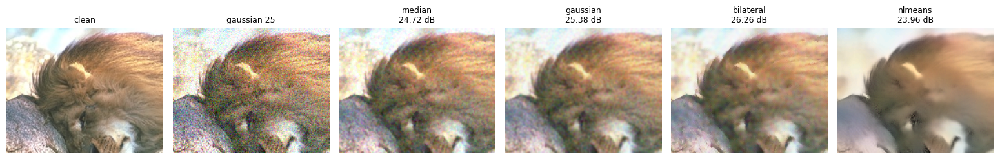

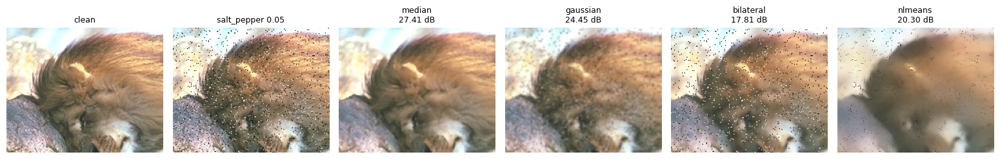

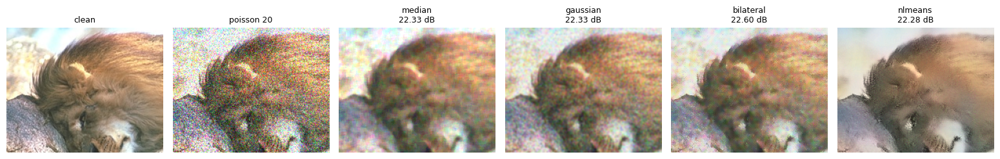

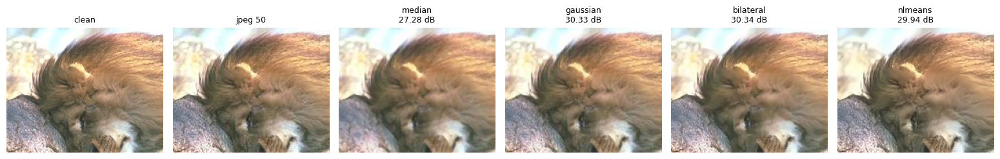

In [20]:
# Qualitative figure: one image, mid severity, degraded + each tuned filter, with a zoomed crop.
def compare_figure(name, sev_idx=2, img_idx=0, box=(60, 220, 120, 320)):
    s = DEGRADATIONS[name][1][sev_idx]
    clean = test_imgs[img_idx]
    noisy = degrade(clean, name, s, noise_rng(img_idx, name, sev_idx))
    outs = [clean, noisy] + [f(noisy, **best[name][str(s)]["per_filter"][k]["params"]) for k, f in FILTERS.items()]
    titles = ["clean", f"{name} {s}"] + [f"{k}\n{psnr(clean, o):.2f} dB" for k, o in zip(FILTERS, outs[2:])]
    r0, r1, c0, c1 = box
    show_grid([o[r0:r1, c0:c1] for o in outs], titles, cols=len(outs), size=2.6,
              save=f"{OUT_DIR}/compare_{name}.png")

for name in ["gaussian", "salt_pepper", "poisson", "jpeg"]:
    compare_figure(name)

**Blind NL-means: how much is knowing σ worth?** The tuned filters were given the true noise level; DnCNN is not. Here σ is estimated from the noisy image itself (`estimate_sigma_haar`): the finest diagonal Haar band of a natural image is almost pure noise, and its median absolute value divided by 0.6745 is a robust estimate of the noise standard deviation. The NL-means strength is then set from a least-squares fit to the tuned settings, $h \approx a\sigma$, and the result is compared with the oracle-tuned NL-means on the same noisy images.

tuned h per sigma: {np.int64(5): np.float64(3.0), np.int64(15): np.float64(10.0), np.int64(25): np.float64(15.0), np.int64(35): np.float64(20.0), np.int64(50): np.float64(30.0)} -> fit h ≈ 0.60·σ
          sigma_hat  sigma_hat_sd  blind  oracle  noisy  \
severity                                                  
5              7.32          2.04  34.37   35.48  34.24   
15            16.07          1.57  28.33   28.36  24.82   
25            24.83          1.76  25.59   25.72  20.53   
35            33.22          2.31  24.06   24.26  17.78   
50            44.98          3.27  22.63   22.94  15.00   

          cost of not knowing σ (dB)  
severity                              
5                               1.11  
15                              0.04  
25                              0.13  
35                              0.20  
50                              0.31  


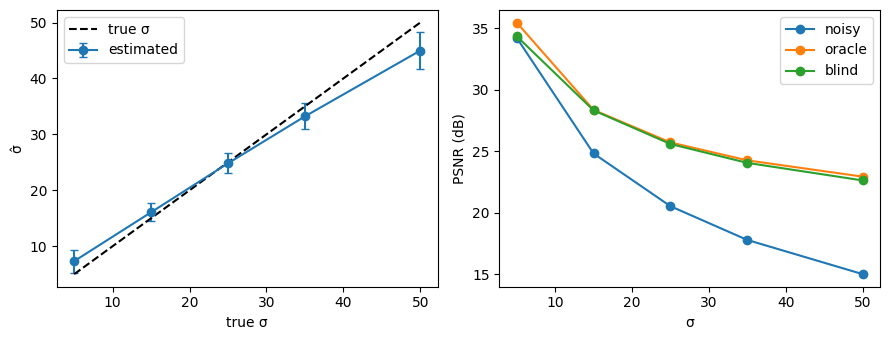

In [22]:
def estimate_sigma_haar(img):
    """Donoho's noise estimate, written out: finest diagonal Haar detail band, robust std via MAD.
    For each 2x2 block [[a, b], [c, d]] the diagonal detail is HH = (a - b - c + d) / 2. In natural images
    this band is almost pure noise; median(|HH|) / 0.6745 turns its median into a Gaussian std."""
    H, W = (img.shape[0] // 2) * 2, (img.shape[1] // 2) * 2
    x = img[:H, :W].astype(np.float64)
    hh = (x[0::2, 0::2] - x[0::2, 1::2] - x[1::2, 0::2] + x[1::2, 1::2]) / 2
    return float(np.mean([np.median(np.abs(hh[..., c])) / 0.6745 for c in range(img.shape[2])]))   # avg over channels

# 1. Fit h ≈ a·σ from the oracle-tuned NL-means settings (least squares through the origin)
sigmas = np.array(DEGRADATIONS["gaussian"][1], float)
h_best = np.array([best["gaussian"][str(s)]["per_filter"]["nlmeans"]["params"]["h"] for s in DEGRADATIONS["gaussian"][1]], float)
a = (h_best @ sigmas) / (sigmas @ sigmas)
print("tuned h per sigma:", dict(zip(sigmas.astype(int), h_best)), f"-> fit h ≈ {a:.2f}·σ")

# 2. Blind NL-means: estimate σ from the noisy image itself, then set h from the fit
def nlmeans_blind(noisy):
    sigma_hat = 255 * estimate_sigma_haar(noisy)   # [0,1] units -> 0-255
    return f_nlmeans(noisy, h=max(1.0, a * sigma_hat)), sigma_hat

# 3. Same test images and same noise as the sweep, so the comparison is paired
rows_b = []
for si, s in enumerate(DEGRADATIONS["gaussian"][1]):
    for i, clean in enumerate(test_imgs):
        noisy = degrade(clean, "gaussian", s, noise_rng(i, "gaussian", si))
        out, sig_hat = nlmeans_blind(noisy)
        rows_b.append(dict(severity=s, image=i, sigma_hat=sig_hat, psnr_blind=psnr(clean, out)))
blind = pd.DataFrame(rows_b)

oracle = df[(df.degradation == "gaussian") & (df["filter"] == "nlmeans")].groupby("severity").psnr.mean()
noisy_p = df[(df.degradation == "gaussian") & (df["filter"] == "none")].groupby("severity").psnr.mean()
res = blind.groupby("severity").agg(sigma_hat=("sigma_hat", "mean"), sigma_hat_sd=("sigma_hat", "std"),
                                    blind=("psnr_blind", "mean"))
res["oracle"] = oracle; res["noisy"] = noisy_p; res["cost of not knowing σ (dB)"] = res.oracle - res.blind
print(res.round(2))

# 4. Plot: estimated vs true σ, and blind vs oracle PSNR
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.5))
a1.errorbar(res.index, res.sigma_hat, yerr=res.sigma_hat_sd, marker="o", capsize=3, label="estimated")
a1.plot(res.index, res.index, "k--", label="true σ"); a1.set_xlabel("true σ"); a1.set_ylabel("σ̂"); a1.legend()
for col in ["noisy", "oracle", "blind"]:
    a2.plot(res.index, res[col], marker="o", label=col)
a2.set_xlabel("σ"); a2.set_ylabel("PSNR (dB)"); a2.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/blind_nlmeans.png", dpi=150); plt.show()

## 6 · Experiment 2: does colour space matter for denoising?

**The idea.** RGB noise is i.i.d. across channels. Each YCrCb channel is a linear combination $w^\top(R, G, B)$, so its noise std is $\sigma\lVert w\rVert_2$:

| Channel | weights | noise std |
|---|---|---|
| Y | (0.299, 0.587, 0.114) | ≈ 0.668 σ |
| Cr | (0.5, −0.419, −0.081) | ≈ 0.657 σ |
| Cb | (−0.169, −0.331, 0.5) | ≈ 0.623 σ |

So the noise is *about the same* in every channel, but natural images put most of their **signal** (edges, texture) in Y and very little in Cr and Cb. The chroma channels therefore have much lower SNR and can take much heavier smoothing without visible loss. Human vision is also less sensitive to chroma detail, the same fact JPEG exploits with 4:2:0 subsampling (notebook 02).

**What the experiment does:**
1. Verifies the noise-std table on a noisy flat-grey image, and measures how much fine detail a clean photo carries in each channel.
2. Shows the Y, Cr and Cb channels of a noisy image side by side; the chroma channels are mostly noise.
3. Compares five configurations of `denoise_in_space` at σ = 15, 25, 50 on the test images (PSNR, SSIM and a crop). The **same filter** (Gaussian blur, strength = its σ) is used everywhere, so colour space is the only variable. `YCrCb (1, 1, 1)` must equal `RGB (1, 1, 1)` exactly, because a linear colour transform commutes with a linear blur, which makes it a built-in bug check.

OpenCV's float32 conversions are used: `COLOR_RGB2YCrCb` (channel order Y, Cr, Cb) and `COLOR_RGB2Lab` (L in 0–100, a and b roughly ±127; the blur does not depend on the scale).

noise std / sigma     theory   measured
  Y                 0.669    0.667
  Cr                0.657    0.658
  Cb                0.623    0.625

clean-image detail std vs noise std (sigma = 25):
  Y    detail 0.0830   noise 0.0654   detail/noise = 1.27
  Cr   detail 0.0040   noise 0.0645   detail/noise = 0.06
  Cb   detail 0.0063   noise 0.0613   detail/noise = 0.10


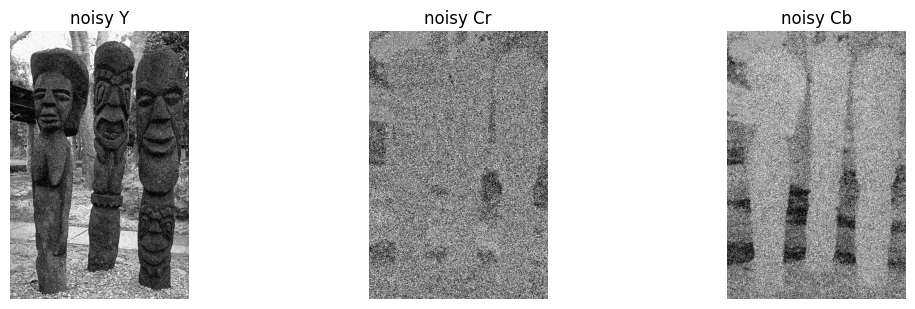

In [23]:
# 6.1 · Verify: noise is about equal in Y, Cr, Cb, but the image's detail is not

# --- (a) Theory: each channel is w · (R, G, B), so its noise std is sigma * ||w||_2 -----------------
W = {"Y":  [0.299, 0.587, 0.114],
     "Cr": [0.5, -0.418688, -0.081312],
     "Cb": [-0.168736, -0.331264, 0.5]}
theory = {k: np.linalg.norm(w) for k, w in W.items()}

# --- (b) Measurement: noise only, on a flat grey image (no image content, so all variation is noise) --
sigma = 25 / 255
flat = np.full((256, 256, 3), 0.5, np.float32)
noise_only = flat + np.random.default_rng(0).normal(0, sigma, flat.shape).astype(np.float32)   # unclipped
ycc = cv2.cvtColor(noise_only, cv2.COLOR_RGB2YCrCb)          # channel order: Y, Cr, Cb
measured = {k: ycc[..., c].std() / sigma for c, k in enumerate(["Y", "Cr", "Cb"])}

print("noise std / sigma     theory   measured")
for k in ["Y", "Cr", "Cb"]:
    print(f"  {k:3s}               {theory[k]:.3f}    {measured[k]:.3f}")

# --- (c) The signal side: how much fine detail each channel carries in a CLEAN photo -------------
# detail = image minus a blurred copy (keeps edges/texture, removes smooth regions)
clean_ycc = cv2.cvtColor(x, cv2.COLOR_RGB2YCrCb)
detail = {k: (clean_ycc[..., c] - cv2.GaussianBlur(clean_ycc[..., c], (0, 0), 2)).std()
          for c, k in enumerate(["Y", "Cr", "Cb"])}
noise_abs = {k: measured[k] * sigma for k in measured}
print("\nclean-image detail std vs noise std (sigma = 25):")
for k in ["Y", "Cr", "Cb"]:
    print(f"  {k:3s}  detail {detail[k]:.4f}   noise {noise_abs[k]:.4f}   detail/noise = {detail[k] / noise_abs[k]:.2f}")

# --- (d) Picture: the three channels of a noisy photo side by side -------------------------------
noisy_ycc = cv2.cvtColor(degrade(x, "gaussian", 25, np.random.default_rng(0)), cv2.COLOR_RGB2YCrCb)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for c, (ax, k) in enumerate(zip(axes, ["Y", "Cr", "Cb"])):
    ch = noisy_ycc[..., c]
    ax.imshow(ch, cmap="gray", vmin=np.percentile(ch, 1), vmax=np.percentile(ch, 99))   # stretch for visibility
    ax.set_title(f"noisy {k}"); ax.axis("off")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/noisy_ycrcb_channels.png", dpi=150); plt.show()

PASS  YCrCb (1,1,1) == RGB (1,1,1): max difference 7.9e-05
done sigma 15
done sigma 25
done sigma 50
                       psnr                   ssim              
sigma                    15      25      50     15     25     50
config                                                          
noisy                24.821  20.527  14.998  0.600  0.424  0.220
RGB (1, 1, 1)        27.086  25.902  22.892  0.768  0.686  0.506
YCrCb (1, 1, 1)      27.086  25.902  22.892  0.768  0.686  0.506
YCrCb (0.7, 2, 2)    29.160  27.416  23.576  0.840  0.752  0.556
YCrCb (2, 0.7, 0.7)  23.880  22.962  20.494  0.560  0.469  0.310
Lab (0.7, 2, 2)      28.766  26.667  22.079  0.823  0.725  0.523
sigma 15: YCrCb (0.7,2,2) beats RGB on 100% of images, mean +2.07 dB
sigma 25: YCrCb (0.7,2,2) beats RGB on 100% of images, mean +1.51 dB
sigma 50: YCrCb (0.7,2,2) beats RGB on 99% of images, mean +0.68 dB


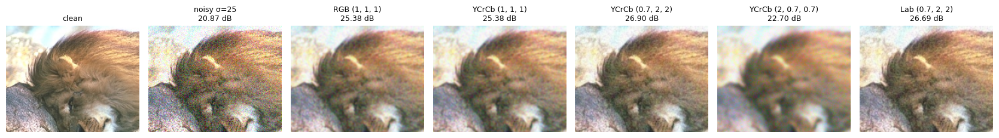

In [24]:
# Colour-space conversions: (to, from) pairs. RGB needs no conversion.
CONVERSIONS = {
    "rgb":   (None, None),
    "ycrcb": (cv2.COLOR_RGB2YCrCb, cv2.COLOR_YCrCb2RGB),   # channels: Y, Cr, Cb  (affine in RGB)
    "lab":   (cv2.COLOR_RGB2Lab,   cv2.COLOR_Lab2RGB),     # channels: L, a, b    (nonlinear: cube root)
}

def denoise_in_space(img, space="rgb", strengths=(1.0, 1.0, 1.0)):
    """Convert to `space`, Gaussian-blur channel c with sigma strengths[c] (0 = leave it alone),
    convert back, clip to [0, 1]. Only the colour space changes between configurations, never the filter."""
    to_space, to_rgb = CONVERSIONS[space]
    z = img.astype(np.float32)
    if to_space is not None:
        z = cv2.cvtColor(z, to_space)               # float32 in -> float32 out (Lab: L in 0-100, a/b ~ +-100)
    channels = []
    for c, s in enumerate(strengths):
        ch = z[..., c]
        if s > 0:
            ch = cv2.GaussianBlur(ch, (0, 0), sigmaX=s, borderType=cv2.BORDER_REFLECT)
        channels.append(ch)
    z = np.stack(channels, axis=-1)
    if to_rgb is not None:
        z = cv2.cvtColor(z, to_rgb)
    return np.clip(z, 0, 1)

SPACE_CONFIGS = {
    "RGB (1, 1, 1)":         ("rgb",   (1.0, 1.0, 1.0)),
    "YCrCb (1, 1, 1)":       ("ycrcb", (1.0, 1.0, 1.0)),   # sanity: must equal RGB (affine transform + linear blur commute)
    "YCrCb (0.7, 2, 2)":     ("ycrcb", (0.7, 2.0, 2.0)),   # gentle luma, heavy chroma (the hypothesis)
    "YCrCb (2, 0.7, 0.7)":   ("ycrcb", (2.0, 0.7, 0.7)),   # the reverse (control)
    "Lab (0.7, 2, 2)":       ("lab",   (0.7, 2.0, 2.0)),
}

# Sanity check before the big loop: YCrCb (1,1,1) must match RGB (1,1,1) on one noisy image
_n = degrade(test_imgs[0], "gaussian", 25, np.random.default_rng(0))
_d = np.abs(denoise_in_space(_n, "rgb", (1, 1, 1)) - denoise_in_space(_n, "ycrcb", (1, 1, 1))).max()
check(_d < 1e-3, f"YCrCb (1,1,1) == RGB (1,1,1): max difference {_d:.1e}")

# Experiment: every config on the SAME noisy image (paired), 3 noise levels, all test images
SIGMAS = [15, 25, 50]
rows_cs = []
for si, s in enumerate(SIGMAS):
    for i, clean in enumerate(test_imgs):
        noisy = degrade(clean, "gaussian", s, np.random.default_rng([SEED, i, 99, si]))
        rows_cs.append(dict(sigma=s, image=i, config="noisy", psnr=psnr(clean, noisy), ssim=ssim(clean, noisy)))
        for name, (space, st) in SPACE_CONFIGS.items():
            out = denoise_in_space(noisy, space, st)
            rows_cs.append(dict(sigma=s, image=i, config=name, psnr=psnr(clean, out), ssim=ssim(clean, out)))
    print("done sigma", s)

cs = pd.DataFrame(rows_cs)
cs.to_csv(f"{OUT_DIR}/colorspace.csv", index=False)
order = ["noisy"] + list(SPACE_CONFIGS)
table_cs = cs.pivot_table(index="config", columns="sigma", values=["psnr", "ssim"], aggfunc="mean").loc[order].round(3)
print(table_cs)

# Paired win rate: does the hypothesis config beat plain RGB on most images, or only on average?
wide = cs.pivot_table(index=["sigma", "image"], columns="config", values="psnr")
for s in SIGMAS:
    w = wide.loc[s]
    diff = w["YCrCb (0.7, 2, 2)"] - w["RGB (1, 1, 1)"]
    print(f"sigma {s}: YCrCb (0.7,2,2) beats RGB on {(diff > 0).mean():.0%} of images, mean {diff.mean():+.2f} dB")

# Figure: zoomed crop of one image at sigma = 25, every config (pick a crop with a smooth coloured area)
def colorspace_figure(img_idx=0, sigma=25, box=(60, 220, 120, 320)):
    clean = test_imgs[img_idx]
    noisy = degrade(clean, "gaussian", sigma, np.random.default_rng([SEED, img_idx, 99, SIGMAS.index(sigma)]))
    outs = [clean, noisy] + [denoise_in_space(noisy, sp, st) for sp, st in SPACE_CONFIGS.values()]
    titles = ["clean", f"noisy σ={sigma}\n{psnr(clean, noisy):.2f} dB"] + \
             [f"{k}\n{psnr(clean, o):.2f} dB" for k, o in zip(SPACE_CONFIGS, outs[2:])]
    r0, r1, c0, c1 = box
    show_grid([o[r0:r1, c0:c1] for o in outs], titles, cols=len(outs), size=2.4,
              save=f"{OUT_DIR}/colorspace_crop.png")

colorspace_figure()

## 7 · Experiment 3: grayscale and contrast

**7.1 · Luma vs average.** The luma weights follow how bright each primary looks to the eye (green most, blue least). Pure red, green and blue patches have the same *average* (1/3) but very different luma (0.299, 0.587, 0.114). The cell shows these patches in colour, as luma grey and as average grey, repeats the comparison on the most saturated test photo, and builds a colour pair that each method maps to the same grey: any conversion from three numbers to one must merge some distinct colours.

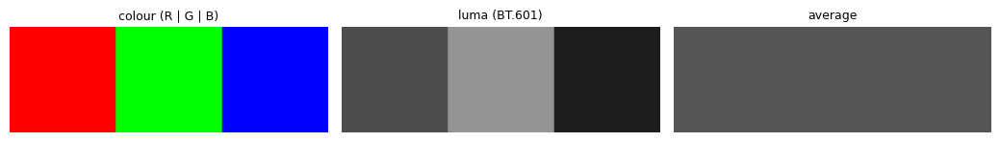

pure R: luma 0.299   average 0.333
pure G: luma 0.587   average 0.333
pure B: luma 0.114   average 0.333


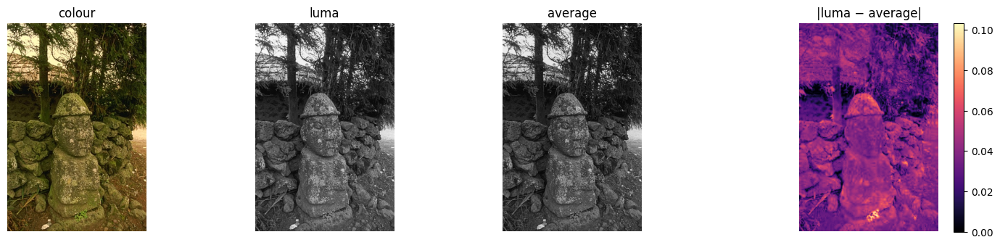

most saturated test image: #78; mean |luma − average| = 0.036, max = 0.103
same AVERAGE (0.5)   red [0.9 0.3 0.3] vs green [0.3 0.9 0.3]:  luma 0.479 / 0.652   average 0.500 / 0.500
same LUMA (0.409)    red [0.9 0.2 0.2] vs green [0.2   0.556 0.2  ]:  luma 0.409 / 0.409   average 0.433 / 0.319


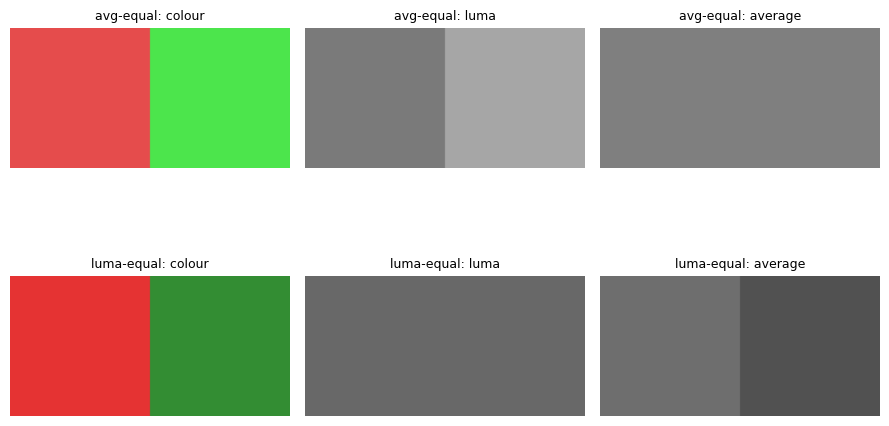

In [25]:
# 7.1 · Luma vs average grayscale

# (a) Synthetic test: pure R, G, B patches have the SAME average (1/3) but very different luma
patch = np.zeros((120, 360, 3), np.float32)
patch[:, :120, 0] = 1      # red
patch[:, 120:240, 1] = 1   # green
patch[:, 240:, 2] = 1      # blue
g_luma, g_avg = D.to_grayscale(patch, "luma"), D.to_grayscale(patch, "average")
show_grid([patch, g_luma, g_avg], ["colour (R | G | B)", "luma (BT.601)", "average"], cols=3, size=3.5,
          save=f"{OUT_DIR}/gray_patches.png")
for k, sl in zip("RGB", [slice(0, 120), slice(120, 240), slice(240, 360)]):
    print(f"pure {k}: luma {g_luma[0, sl][0, 0]:.3f}   average {g_avg[0, sl][0, 0]:.3f}")

# (b) Real photo: pick the most saturated test image, where the two methods should differ most
def mean_saturation(img):
    return cv2.cvtColor(img.astype(np.float32), cv2.COLOR_RGB2HSV)[..., 1].mean()
k_sat = int(np.argmax([mean_saturation(im) for im in test_imgs]))
photo = test_imgs[k_sat]
gl, ga = D.to_grayscale(photo, "luma"), D.to_grayscale(photo, "average")
diff = np.abs(gl[..., 0] - ga[..., 0])
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, im, t in zip(axes, [photo, gl, ga], ["colour", "luma", "average"]):
    ax.imshow(np.clip(im, 0, 1)); ax.set_title(t); ax.axis("off")
hm = axes[3].imshow(diff, cmap="magma"); axes[3].set_title("|luma − average|"); axes[3].axis("off")
plt.colorbar(hm, ax=axes[3], fraction=0.046)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/gray_photo.png", dpi=150); plt.show()
print(f"most saturated test image: #{k_sat}; mean |luma − average| = {diff.mean():.3f}, max = {diff.max():.3f}")

# (c) Every grayscale merges some distinct colours. Two pairs, each "invisible" to one method:
W_LUMA, W_AVG = np.array([0.299, 0.587, 0.114]), np.ones(3) / 3
pairs = {"same AVERAGE (0.5)": (np.array([0.9, 0.3, 0.3]), np.array([0.3, 0.9, 0.3])),
         "same LUMA (0.409)":  (np.array([0.9, 0.2, 0.2]), np.array([0.2, 0.556, 0.2]))}
swatches = []
for label, (c1, c2) in pairs.items():
    print(f"{label:20s} red {c1} vs green {c2}:  luma {c1 @ W_LUMA:.3f} / {c2 @ W_LUMA:.3f}"
          f"   average {c1 @ W_AVG:.3f} / {c2 @ W_AVG:.3f}")
    sw = np.zeros((80, 160, 3), np.float32); sw[:, :80] = c1; sw[:, 80:] = c2
    swatches += [sw, D.to_grayscale(sw, "luma"), D.to_grayscale(sw, "average")]
show_grid(swatches, [f"{l}: {t}" for l in ["avg-equal", "luma-equal"] for t in ("colour", "luma", "average")],
          cols=3, size=3, save=f"{OUT_DIR}/gray_metamers.png")


**7.2 · Histogram equalisation vs CLAHE on low-light images.**

- *Global HE* maps intensities through the image's own cumulative histogram. This spreads the histogram but amplifies noise, and shifts colours when applied to each RGB channel separately (each channel gets a different curve).
- *CLAHE* equalises small tiles with a **clip limit** on the histogram, which caps how much contrast (and noise) it can add, then blends the tiles bilinearly.
- Applying either to **only the L channel of Lab** changes brightness while leaving hue (a, b) alone.

Four versions are compared on `low_light` at ℓ = 0.6 and 0.8: HE per RGB channel, HE on L, CLAHE per RGB channel and CLAHE on L. Each is scored with PSNR and SSIM against the clean image, and with a colour-shift score: the mean distance between the clean and output images in the (a, b) plane of Lab. PSNR stays low even when an image looks much better, because equalisation does not restore the original absolute brightness: another case where a metric disagrees with appearance.

PASS  functions run, shapes kept
PASS  color_shift: 0 for identical, >0 for grey
mean brightness of the clean images: 0.409
            brightness        color_shift            psnr           ssim  \
level              0.6    0.8         0.6     0.8     0.6     0.8    0.6   
method                                                                     
degraded         0.111  0.071      15.038  17.231   9.860   8.628  0.214   
HE (RGB)         0.423  0.371      38.615  47.966  13.322  11.522  0.260   
HE (L)           0.459  0.449      14.885  17.039  14.478  12.979  0.332   
CLAHE (RGB)      0.224  0.166      22.981  25.958  13.144  10.922  0.305   
CLAHE (L)        0.208  0.153      15.060  17.252  12.827  10.754  0.383   

                    
level          0.8  
method              
degraded     0.119  
HE (RGB)     0.161  
HE (L)       0.227  
CLAHE (RGB)  0.183  
CLAHE (L)    0.248  


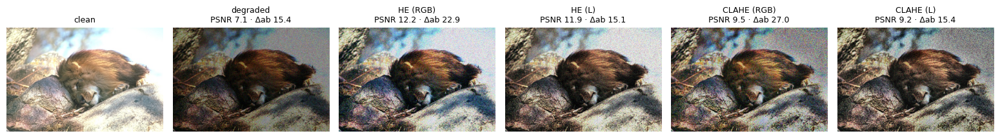

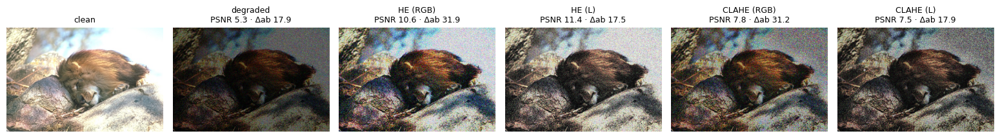

In [26]:
# 7.2 · Histogram equalisation vs CLAHE on low-light images
# All functions take/return float RGB in [0, 1]; OpenCV's equalisers need uint8, so convert at the edges.

def _per_channel(img, fn):
    u8 = to_u8(img)
    return from_u8(np.stack([fn(u8[..., c]) for c in range(3)], axis=-1))

def _on_L(img, fn):
    lab = cv2.cvtColor(to_u8(img), cv2.COLOR_RGB2Lab)      # uint8 Lab: L scaled to 0-255, a/b offset by 128
    lab[..., 0] = fn(lab[..., 0])                            # change brightness only; a, b (the colour) untouched
    return from_u8(cv2.cvtColor(lab, cv2.COLOR_Lab2RGB))

def hist_eq_rgb(img):
    """Global HE on each RGB channel separately: each channel gets its OWN curve -> colours shift."""
    return _per_channel(img, cv2.equalizeHist)

def hist_eq_L(img):
    """Global HE on Lab's L channel only."""
    return _on_L(img, cv2.equalizeHist)

def clahe_rgb(img, clip=2.0, tiles=8):
    """CLAHE per RGB channel: local tiles, histogram clipped at `clip` to cap contrast (and noise) gain."""
    cl = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles))
    return _per_channel(img, cl.apply)

def clahe_L(img, clip=2.0, tiles=8):
    cl = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles))
    return _on_L(img, cl.apply)

def color_shift(ref, out):
    """Mean distance between ref and out in Lab's (a, b) plane: how much the COLOUR changed, ignoring brightness.
    Float Lab from OpenCV: a, b roughly in [-127, 127]."""
    a = cv2.cvtColor(ref.astype(np.float32), cv2.COLOR_RGB2Lab)[..., 1:]
    b = cv2.cvtColor(out.astype(np.float32), cv2.COLOR_RGB2Lab)[..., 1:]
    return float(np.mean(np.sqrt(((a - b) ** 2).sum(-1))))

# Quick checks
check(np.allclose(hist_eq_L(x), hist_eq_L(x)) and hist_eq_rgb(x).shape == x.shape, "functions run, shapes kept")
check(color_shift(x, x) < 1e-6 and color_shift(x, D.to_grayscale(x)) > 1, "color_shift: 0 for identical, >0 for grey")

# Experiment
ENHANCERS = {"degraded": lambda im: im, "HE (RGB)": hist_eq_rgb, "HE (L)": hist_eq_L,
             "CLAHE (RGB)": clahe_rgb, "CLAHE (L)": clahe_L}
LEVELS = [0.6, 0.8]
rows_he = []
for li, lv in enumerate(LEVELS):
    for i, clean in enumerate(test_imgs):
        dark = degrade(clean, "low_light", lv, np.random.default_rng([SEED, i, 77, li]))
        for name, f in ENHANCERS.items():
            out = np.clip(f(dark), 0, 1)
            rows_he.append(dict(level=lv, image=i, method=name, psnr=psnr(clean, out), ssim=ssim(clean, out),
                                color_shift=color_shift(clean, out), brightness=out.mean()))
he = pd.DataFrame(rows_he)
he.to_csv(f"{OUT_DIR}/contrast_enhancement.csv", index=False)
clean_brightness = np.mean([im.mean() for im in test_imgs])
table_he = he.pivot_table(index="method", columns="level", values=["psnr", "ssim", "color_shift", "brightness"],
                          aggfunc="mean").loc[list(ENHANCERS)].round(3)
print(f"mean brightness of the clean images: {clean_brightness:.3f}")
print(table_he)

# Figure: one image, both levels, every method
def contrast_figure(img_idx=0):
    clean = test_imgs[img_idx]
    for li, lv in enumerate(LEVELS):
        dark = degrade(clean, "low_light", lv, np.random.default_rng([SEED, img_idx, 77, li]))
        outs = [clean] + [np.clip(f(dark), 0, 1) for f in ENHANCERS.values()]
        titles = ["clean"] + [f"{k}\nPSNR {psnr(clean, o):.1f} · Δab {color_shift(clean, o):.1f}"
                              for k, o in zip(ENHANCERS, outs[1:])]
        show_grid(outs, titles, cols=len(outs), size=2.6, save=f"{OUT_DIR}/contrast_level{lv}.png")

contrast_figure()

## 7.5 · Fixes that match the degradation

Section 5 shows that **no denoiser helps with blur or colour cast**: their best "gain" is about zero or negative, because those are not noise problems. Each has its own classical inverse:

- **Colour cast → gray-world white balance.** Assumes the scene averages to grey and scales each channel by $\bar g / \bar c$, where $\bar c$ is the channel mean and $\bar g$ the mean over all channels. The cell measures how much of the cast it removes (PSNR and `color_shift` against the clean image), and shows the test image where the assumption fails worst: the one dominated by a single colour.
- **Blur → Wiener deconvolution.** With the blur kernel known, the blur is inverted in the frequency domain with a regulariser: $\hat X = \frac{H^*}{|H|^2 + K} Y$, per channel, with a Gaussian PSF of the same σ. Sweeping $K$ shows the trade-off: small $K$ sharpens but amplifies noise, large $K$ stays blurry. Adding a little Gaussian noise (σ = 2) shows why the regulariser is needed.

Both make the same point: *restoration has to match the degradation model*. The same reason explains why a DnCNN trained only on Gaussian noise struggles on other damage in notebooks 05 and 06.

PASS  gray_world leaves a grey image unchanged
PASS  Wiener improves a noise-free blurred image
Colour cast:
          color_shift              psnr        best denoiser psnr
method    gray-world   none gray-world   none                   
strength                                                        
0.1            13.39   7.18      26.45  29.24              29.10
0.2            13.49  14.34      25.82  23.39              23.41
0.3            13.66  21.40      25.09  20.03              20.15
0.4            13.85  28.25      24.35  17.68              17.85
0.5            14.11  34.74      23.61  15.89              16.08

Most colour-dominated clean image: #15 (channel means [0.22  0.495 0.56 ])
  gray-world on the CLEAN image: PSNR 15.72 dB, colour shift 21.1  (a perfect method would change nothing)


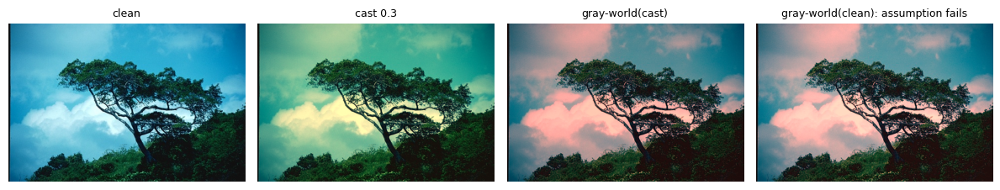

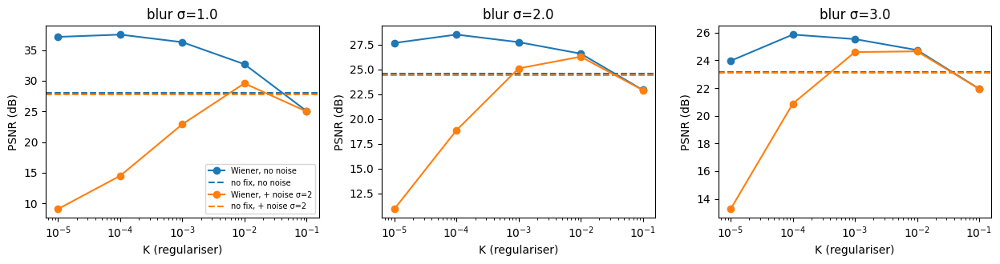


Blur:
    blur        noise   none  best_K  wiener  best_denoiser
0   1.0     no noise  28.03  0.0001   37.53          27.77
1   1.0  + noise σ=2  27.81    0.01   29.57            NaN
2   2.0     no noise  24.55  0.0001   28.52          24.48
3   2.0  + noise σ=2  24.45    0.01   26.29            NaN
4   3.0     no noise  23.17  0.0001   25.86          23.13
5   3.0  + noise σ=2  23.10    0.01   24.65            NaN


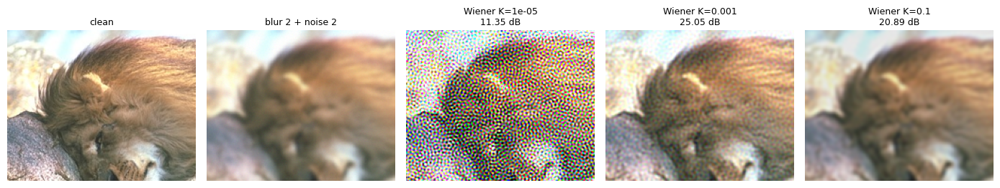

In [27]:
# 7.5 · Fixes that match the degradation: gray-world white balance and Wiener deconvolution

# ---------------------------------------------------------------- (a) colour cast -> gray-world
def gray_world(img):
    """Assume the scene averages to grey: scale each channel so its mean equals the overall mean."""
    means = img.reshape(-1, 3).mean(0)                     # per-channel means (R, G, B)
    gains = means.mean() / np.maximum(means, 1e-6)
    return np.clip(img * gains, 0, 1)

# ---------------------------------------------------------------- (b) blur -> Wiener deconvolution
def gaussian_psf(sigma, size):
    """Normalised 2-D Gaussian kernel (sums to 1), size x size, centred."""
    r = np.arange(size) - size // 2
    g = np.exp(-(r ** 2) / (2 * sigma ** 2))
    k = np.outer(g, g)
    return k / k.sum()

def wiener_deblur(img, sigma, K=1e-2):
    """X = conj(H) / (|H|^2 + K) * Y, per channel, in the frequency domain.
    K is the regulariser: K -> 0 is the pure inverse filter (amplifies noise where |H| ~ 0);
    larger K stays blurrier but stable. The FFT assumes the image wraps around, so pad with a
    reflection first (otherwise the edges ring) and crop afterwards."""
    pad = int(np.ceil(4 * sigma)) + 8
    y = np.pad(img.astype(np.float64), ((pad, pad), (pad, pad), (0, 0)), mode="reflect")
    H_, W_ = y.shape[:2]
    size = 2 * int(np.ceil(4 * sigma)) + 1
    psf = np.zeros((H_, W_))
    psf[:size, :size] = gaussian_psf(sigma, size)
    psf = np.roll(psf, (-(size // 2), -(size // 2)), axis=(0, 1))   # move kernel centre to (0, 0)
    H = np.fft.fft2(psf)
    G = np.conj(H) / (np.abs(H) ** 2 + K)
    out = np.stack([np.real(np.fft.ifft2(np.fft.fft2(y[..., c]) * G)) for c in range(3)], axis=-1)
    return np.clip(out[pad:-pad, pad:-pad], 0, 1).astype(np.float32)

# Checks
_x = test_imgs[0]
check(np.allclose(gray_world(np.full((8, 8, 3), 0.4, np.float32)), 0.4), "gray_world leaves a grey image unchanged")
_b = degrade(_x, "blur", 2.0, None)
check(psnr(_x, wiener_deblur(_b, 2.0, 1e-3)) > psnr(_x, _b), "Wiener improves a noise-free blurred image")

def best_denoiser_psnr(name, s):
    """Best classical denoiser's mean test PSNR from Section 5 (for comparison), or NaN if not run."""
    try:
        sub = df[(df.degradation == name) & (df.severity == s) & (df["filter"] != "none")]
        return sub.groupby("filter").psnr.mean().max()
    except NameError:
        return np.nan

# ---------------------------------------------------------------- Experiment A: colour cast
rows_cc = []
for s in DEGRADATIONS["color_cast"][1]:
    for i, clean in enumerate(test_imgs):
        cast = degrade(clean, "color_cast", s, None)
        for method, out in [("none", cast), ("gray-world", gray_world(cast))]:
            rows_cc.append(dict(strength=s, image=i, method=method, psnr=psnr(clean, out),
                                color_shift=color_shift(clean, out)))
cc = pd.DataFrame(rows_cc)
tab_cc = cc.pivot_table(index="strength", columns="method", values=["psnr", "color_shift"], aggfunc="mean").round(2)
tab_cc["best denoiser psnr"] = [round(best_denoiser_psnr("color_cast", s), 2) for s in tab_cc.index]
print("Colour cast:\n", tab_cc)

# Where the gray-world assumption fails: the clean image whose channels are most unbalanced already
imbalance = [np.ptp(im.reshape(-1, 3).mean(0)) for im in test_imgs]
k_bad = int(np.argmax(imbalance))
clean_bad = test_imgs[k_bad]
print(f"\nMost colour-dominated clean image: #{k_bad} (channel means {np.round(clean_bad.reshape(-1, 3).mean(0), 3)})")
print(f"  gray-world on the CLEAN image: PSNR {psnr(clean_bad, gray_world(clean_bad)):.2f} dB, "
      f"colour shift {color_shift(clean_bad, gray_world(clean_bad)):.1f}  (a perfect method would change nothing)")
cast_bad = degrade(clean_bad, "color_cast", 0.3, None)
show_grid([clean_bad, cast_bad, gray_world(cast_bad), gray_world(clean_bad)],
          ["clean", "cast 0.3", "gray-world(cast)", "gray-world(clean): assumption fails"],
          cols=4, size=3, save=f"{OUT_DIR}/grayworld_failure.png")

# ---------------------------------------------------------------- Experiment B: blur, K sweep
K_GRID = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
BLURS = [1.0, 2.0, 3.0]
EXTRA_NOISE = {"no noise": 0, "+ noise σ=2": 2}         # tiny noise on top of the blur shows why K exists
rows_w = []
for bi, bs in enumerate(BLURS):
    for i, clean in enumerate(test_imgs):
        blurred = degrade(clean, "blur", bs, None)
        for nlabel, ns in EXTRA_NOISE.items():
            inp = blurred if ns == 0 else degrade(blurred, "gaussian", ns, np.random.default_rng([SEED, i, 55, bi]))
            rows_w.append(dict(blur=bs, noise=nlabel, image=i, K="none", psnr=psnr(clean, inp)))
            for K in K_GRID:
                rows_w.append(dict(blur=bs, noise=nlabel, image=i, K=K, psnr=psnr(clean, wiener_deblur(inp, bs, K))))
wd = pd.DataFrame(rows_w)

fig, axes = plt.subplots(1, len(BLURS), figsize=(4.2 * len(BLURS), 3.4), sharey=False)
for ax, bs in zip(axes, BLURS):
    for nlabel in EXTRA_NOISE:
        sub = wd[(wd.blur == bs) & (wd.noise == nlabel)]
        curve = sub[sub.K != "none"].groupby("K").psnr.mean()
        line, = ax.semilogx(curve.index.astype(float), curve.values, marker="o", label=f"Wiener, {nlabel}")
        ax.axhline(sub[sub.K == "none"].psnr.mean(), ls="--", color=line.get_color(), label=f"no fix, {nlabel}")
    ax.set_title(f"blur σ={bs}"); ax.set_xlabel("K (regulariser)"); ax.set_ylabel("PSNR (dB)")
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/wiener_K_sweep.png", dpi=150); plt.show()

summary_w = []
for bs in BLURS:
    for nlabel in EXTRA_NOISE:
        sub = wd[(wd.blur == bs) & (wd.noise == nlabel)]
        m = sub[sub.K != "none"].groupby("K").psnr.mean()
        summary_w.append(dict(blur=bs, noise=nlabel, none=sub[sub.K == "none"].psnr.mean(),
                              best_K=f"{m.idxmax():g}", wiener=m.max(),
                              best_denoiser=best_denoiser_psnr("blur", bs) if nlabel == "no noise" else np.nan))
print("\nBlur:\n", pd.DataFrame(summary_w).round(2))

# Visual: blur σ=2 with a little noise, K too small / about right / too large
clean = test_imgs[0]
inp = degrade(degrade(clean, "blur", 2.0, None), "gaussian", 2, np.random.default_rng(0))
r0, r1, c0, c1 = 60, 220, 120, 320
outs = [clean, inp] + [wiener_deblur(inp, 2.0, K) for K in (1e-5, 1e-3, 1e-1)]
show_grid([o[r0:r1, c0:c1] for o in outs],
          ["clean", "blur 2 + noise 2"] + [f"Wiener K={K:g}\n{psnr(clean, o):.2f} dB" for K, o in zip((1e-5, 1e-3, 1e-1), outs[2:])],
          cols=5, size=2.8, save=f"{OUT_DIR}/wiener_examples.png")

## 8 · Wrap-up

Builds the summary table (best filter and gain per condition, test-set PSNR), saved as `best_filter_table.md`, and checks that every file the later notebooks need exists. On Kaggle, committing the notebook (**Save Version → Save & Run All**) publishes these files as the notebook's output, which notebooks 05 and 06 attach as an input.

In [28]:
# Best filter per degradation at each severity (test-set PSNR), saved as a markdown table
means = df.groupby(["degradation", "severity", "filter"]).psnr.mean().reset_index()
noisy_ref = means[means["filter"] == "none"].set_index(["degradation", "severity"]).psnr
filt = means[means["filter"] != "none"]
top = filt.loc[filt.groupby(["degradation", "severity"]).psnr.idxmax()].set_index(["degradation", "severity"])
table = pd.DataFrame({"noisy PSNR": noisy_ref, "best filter": top["filter"], "best PSNR": top.psnr})
table["gain (dB)"] = table["best PSNR"] - table["noisy PSNR"]
table = table.round(2)
with open(f"{OUT_DIR}/best_filter_table.md", "w") as fh:
    try:
        fh.write(table.to_markdown())
    except ImportError:          # to_markdown needs the `tabulate` package
        fh.write(table.to_string())
table

noisy PSNR best filter  best PSNR  gain (dB)
degradation severity                                              
blur        0.50           36.67   bilateral      35.26      -1.41
            1.00           28.03   bilateral      27.77      -0.26
            1.50           25.76   bilateral      25.64      -0.13
            2.00           24.55   bilateral      24.48      -0.07
            3.00           23.17      median      23.13      -0.03
color_cast  0.10           29.24   bilateral      29.10      -0.14
            0.20           23.39     nlmeans      23.41       0.02
            0.30           20.03     nlmeans      20.15       0.13
            0.40           17.68     nlmeans      17.85       0.17
            0.50           15.89     nlmeans      16.08       0.19
gaussian    5.00           34.24   bilateral      37.65       3.41
            15.00          24.82   bilateral      30.90       6.08
            25.00          20.53   bilateral      27.56       7.03
            35.00          17.78   bilateral      25.73       7.95
            50.00          15.00    gaussian      23.20       8.20
jpeg        10.00          25.72   bilateral      26.25       0.54
            30.00          29.31   bilateral      29.70       0.39
            50.00          31.01   bilateral      31.36       0.35
            70.00          32.87   bilateral      33.14       0.27
            90.00          37.33   bilateral      37.68       0.34
low_light   0.20           16.18   bilateral      16.30       0.12
            0.40           11.95    gaussian      11.99       0.04
            0.60            9.86    gaussian       9.89       0.03
            0.80            8.63    gaussian       8.66       0.03
            0.90            8.20    gaussian       8.24       0.04
poisson     5.00           12.18    gaussian      21.67       9.48
            10.00          14.79    gaussian      23.13       8.34
            20.00          17.56   bilateral      25.15       7.59
            50.00          21.36   bilateral      27.81       6.45
            100.00         24.30   bilateral      29.87       5.57
salt_pepper 0.01           24.98      median      29.00       4.02
            0.03           20.23      median      28.83       8.60
            0.05           18.00      median      28.64      10.64
            0.10           14.99      median      28.03      13.04
            0.20           11.98      median      25.61      13.63

In [29]:
needed = ["degradations.py", f"{OUT_DIR}/baselines.csv", f"{OUT_DIR}/best_classical.json",
          f"{OUT_DIR}/severity_psnr.png", f"{OUT_DIR}/severity_ssim.png"]
for p in needed:
    check(os.path.exists(p), p)
check(len(test_imgs) >= 60, f"results use the real test set ({len(test_imgs)} test images)")

PASS  degradations.py
PASS  /kaggle/working/outputs/01/baselines.csv
PASS  /kaggle/working/outputs/01/best_classical.json
PASS  /kaggle/working/outputs/01/severity_psnr.png
PASS  /kaggle/working/outputs/01/severity_ssim.png
PASS  results use the real test set (96 test images)


True

### Common bugs this notebook guards against
- **uint8 overflow:** `u8 + noise` wraps around at 255, so noise is always added in float.
- **BGR vs RGB:** OpenCV reads and writes BGR. `load_rgb` converts once, at loading.
- **Clipping before the metric:** `degrade()` and the filters clip to [0, 1], so every PSNR is computed on valid images.
- **Same noise for every image:** each (image, degradation, severity) gets its own seeded generator from `noise_rng`.
- **JPEG and Poisson severities run backwards:** a lower quality or photon count is *more* severe; the plots reorder them mild → severe.

## Findings

- **Gaussian and Poisson noise:** the bilateral filter worked best at most levels (+7.03 dB at σ = 25). At the heaviest noise, a plain Gaussian blur did better.
- **Salt & pepper:** the median filter won at every level (+10.64 dB at 0.05). One wrong pixel can't move a median, so it removes the specks without blurring much.
- **JPEG:** the best filter (bilateral) gained only +0.27 to +0.54 dB, by smoothing the block edges.
- **Blur and colour cast:** no denoiser helped (best gains −1.41 to +0.19 dB), because these are not noise problems. Fixes made for them did work: gray-world took colour cast 0.3 from 20.03 to 25.09 dB, and Wiener deconvolution took blur 1.0 from 28.03 to 37.53 dB. So the repair has to match the damage.
- **Colour space:** blurring brightness gently and colour heavily, YCrCb (0.7, 2, 2), beat plain RGB by +2.07 / +1.51 / +0.68 dB at σ = 15 / 25 / 50, on 99–100% of images. The colour channels carry very little detail, so they can be smoothed much more.
- **Blind NL-means:** not knowing σ cost only 0.04–0.31 dB for σ ≥ 15, so the tuned filters are a fair, strong baseline even though they were told the noise level.
- **Baseline for notebook 04:** the best classical PSNR on Gaussian noise is 30.90 / 27.56 / 23.20 dB at σ = 15 / 25 / 50.